# Поиск общих ключевых точек на изображениях планктона

## 1. Импорты и параметры эксперимента

SIFT работает с градациями серого, поэтому цвет для вычисления дескриптора не нужен. Исходные изображения не изменяются: уменьшенные копии используются только для анализа. Все численные параметры собраны в одной ячейке.

In [ ]:
from itertools import combinations
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_DIR = Path.cwd()
IMAGE_DIR = PROJECT_DIR / "images"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

MAX_IMAGE_SIDE = 1400
SIFT_FEATURE_LIMIT = 3000
CONTRAST_THRESHOLD = 0.025
EDGE_THRESHOLD = 12
SIFT_SIGMA = 1.6
LOWE_RATIO = 0.75
RANSAC_THRESHOLD_PX = 5.0
MAX_DISPLAY_POINTS = 30

cv2.setRNGSeed(42)
plt.rcParams["font.family"] = "DejaVu Sans"

## 2. Загрузка и подготовка изображений

Сохраняем пропорции при уменьшении до 1400 px по длинной стороне. Масштаб понадобится, если позже потребуется перевести найденные координаты обратно к исходным снимкам.

In [2]:
image_paths = sorted(IMAGE_DIR.glob("*.jpg"))
if len(image_paths) < 2:
    raise FileNotFoundError(
        f"В {IMAGE_DIR} должно быть минимум два JPG-изображения. "
        "Запустите ноутбук из корня проекта."
    )

images_bgr = []
images_gray = []
original_sizes = []
scales = []

for image_path in image_paths:
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Не удалось прочитать изображение: {image_path}")

    height, width = image.shape[:2]
    scale = min(1.0, MAX_IMAGE_SIDE / max(height, width))
    resized_width = round(width * scale)
    resized_height = round(height * scale)

    if scale < 1.0:
        image = cv2.resize(
            image,
            (resized_width, resized_height),
            interpolation=cv2.INTER_AREA,
        )

    images_bgr.append(image)
    images_gray.append(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY))
    original_sizes.append((width, height))
    scales.append(scale)

image_info = pd.DataFrame(
    {
        "Изображение": [path.name for path in image_paths],
        "Исходный размер": [f"{w} × {h}" for w, h in original_sizes],
        "После обработки": [
            f"{image.shape[1]} × {image.shape[0]}" for image in images_bgr
        ],
        "Масштаб": np.round(scales, 3),
    }
)
display(image_info)

,Изображение,Исходный размер,После обработки,Масштаб
0,Bosmina longirostris 1.jpg,2592 × 1944,1400 × 1050,0.540
1,Bosmina longirostris 2.jpg,3005 × 2513,1400 × 1171,0.466
2,Bosmina longirostris 3.jpg,1608 × 1944,1158 × 1400,0.720
3,Bosmina longirostris 4.jpg,1959 × 1760,1400 × 1258,0.715
4,Bosmina longirostris 5.jpg,2170 × 2094,1400 × 1351,0.645
5,Bosmina longirostris 6.jpg,778 × 632,778 × 632,1.000


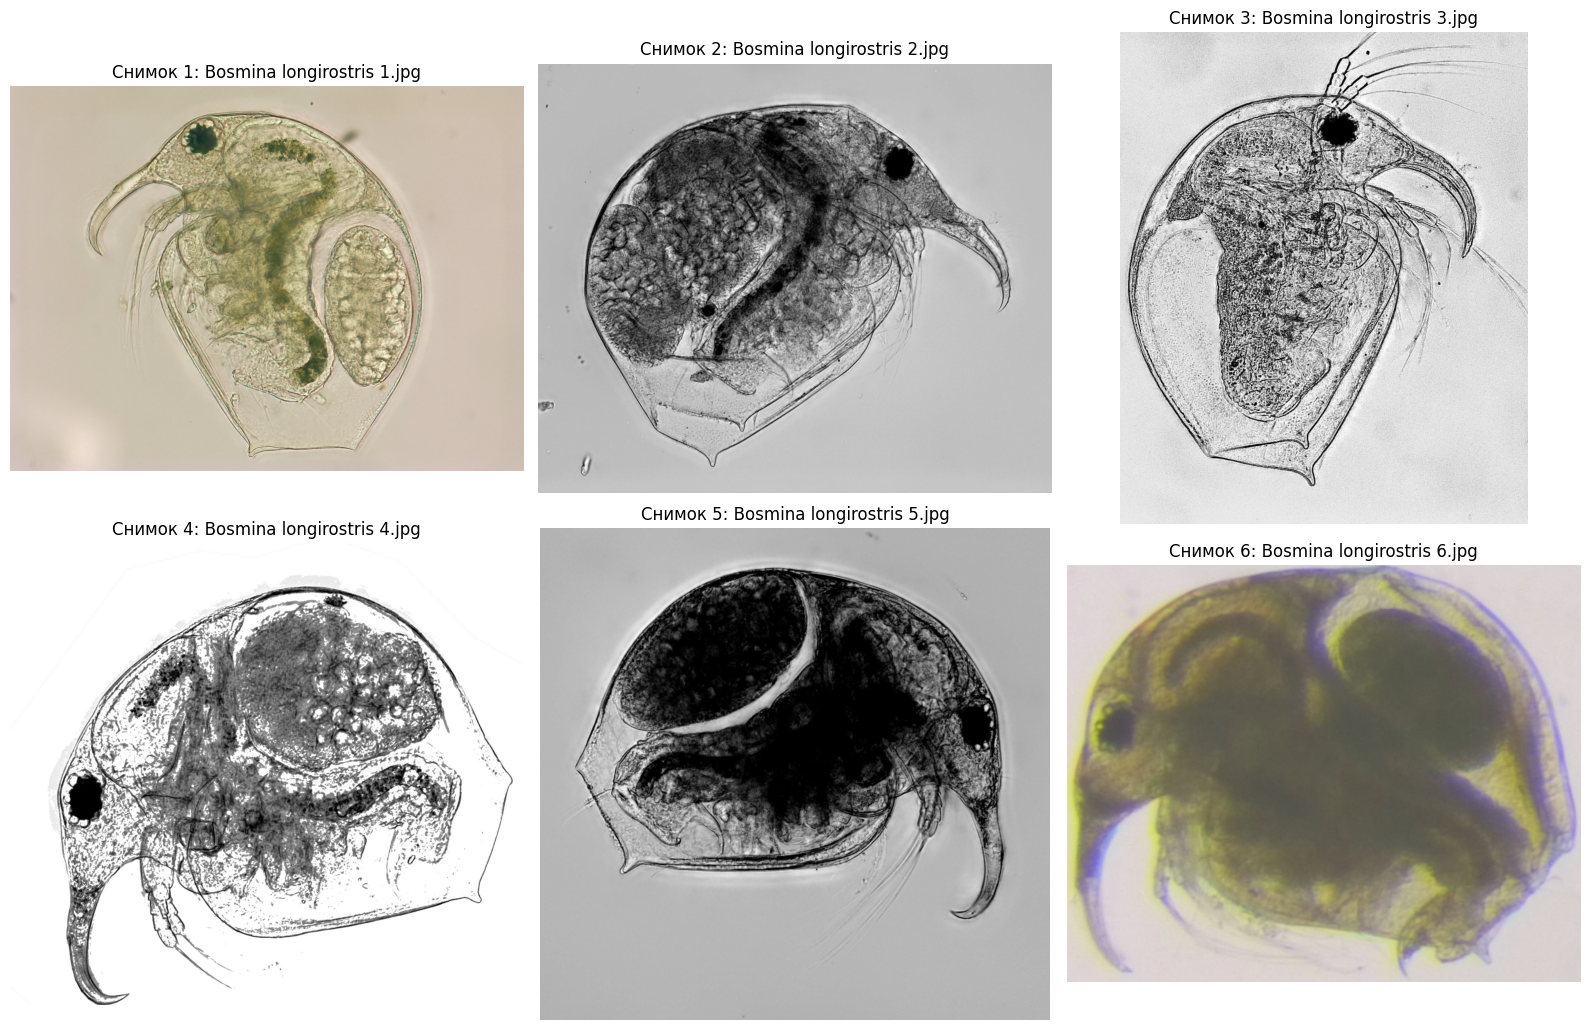

In [3]:
def show_image_grid(images, titles, save_to=None, points=None):
    """Показывает шесть изображений и, если есть, одинаково нумерует точки."""
    columns = 3
    rows = int(np.ceil(len(images) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(16, 5.2 * rows))
    axes = np.array(axes).reshape(-1)

    for image_index, (image, title) in enumerate(zip(images, titles)):
        axis = axes[image_index]
        rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        axis.imshow(rgb_image)
        axis.set_title(title, fontsize=12)
        axis.axis("off")

        if points is not None:
            for label, x, y in points[image_index]:
                axis.scatter(x, y, s=80, c="red", edgecolors="white")
                axis.text(x + 8, y - 8, str(label), color="red", fontsize=11,
                          weight="bold", path_effects=[])

    for axis in axes[len(images):]:
        axis.axis("off")

    fig.tight_layout()
    if save_to is not None:
        fig.savefig(save_to, dpi=135, bbox_inches="tight")
    plt.show()


image_titles = [f"Снимок {index}: {path.name}" for index, path in enumerate(image_paths, 1)]
show_image_grid(images_bgr, image_titles, RESULTS_DIR / "originals.jpg")

## 3. Детектор SIFT и его параметры

SIFT выделяет локальные экстремумы Difference of Gaussians и описывает окружение точки **128-мерным вектором** градиентов. Ниже параметры OpenCV:

| Параметр | Значение | Значение для эксперимента |
|---|---:|---|
| `nfeatures` | `3000` | Ограничивает число сохранённых сильнейших точек. |
| `contrastThreshold` | `0.025` | Пониженный порог сохраняет более слабые особенности на малоконтрастных снимках. |
| `edgeThreshold` | `12` | Регулирует отсеивание откликов, похожих на границы (большее значение сохраняет больше точек). |
| `sigma` | `1.6` | Начальное гауссово сглаживание для масштабного пространства. |

**Важно:** SIFT относительно устойчив к повороту и масштабированию *одного и того же локального рисунка*, но не гарантирует одинаковых точек у разных организмов.

In [4]:
sift = cv2.SIFT_create(
    nfeatures=SIFT_FEATURE_LIMIT,
    contrastThreshold=CONTRAST_THRESHOLD,
    edgeThreshold=EDGE_THRESHOLD,
    sigma=SIFT_SIGMA,
)

keypoints = []
descriptors = []

for gray_image in images_gray:
    image_keypoints, image_descriptors = sift.detectAndCompute(gray_image, None)
    if image_descriptors is None:
        raise RuntimeError("SIFT не нашёл дескрипторы на одном из изображений")

    keypoints.append(image_keypoints)
    descriptors.append(image_descriptors)

keypoints_table = pd.DataFrame(
    {
        "Снимок": range(1, len(image_paths) + 1),
        "Число ключевых точек": [len(points) for points in keypoints],
        "Размерность дескриптора": [desc.shape[1] for desc in descriptors],
    }
)
display(keypoints_table)
print(f"Всего SIFT-точек: {sum(len(points) for points in keypoints):,}")

,Снимок,Число ключевых точек,Размерность дескриптора
0,1,3000,128
1,2,3000,128
2,3,3000,128
3,4,3001,128
4,5,3000,128
5,6,378,128


Всего SIFT-точек: 15,379


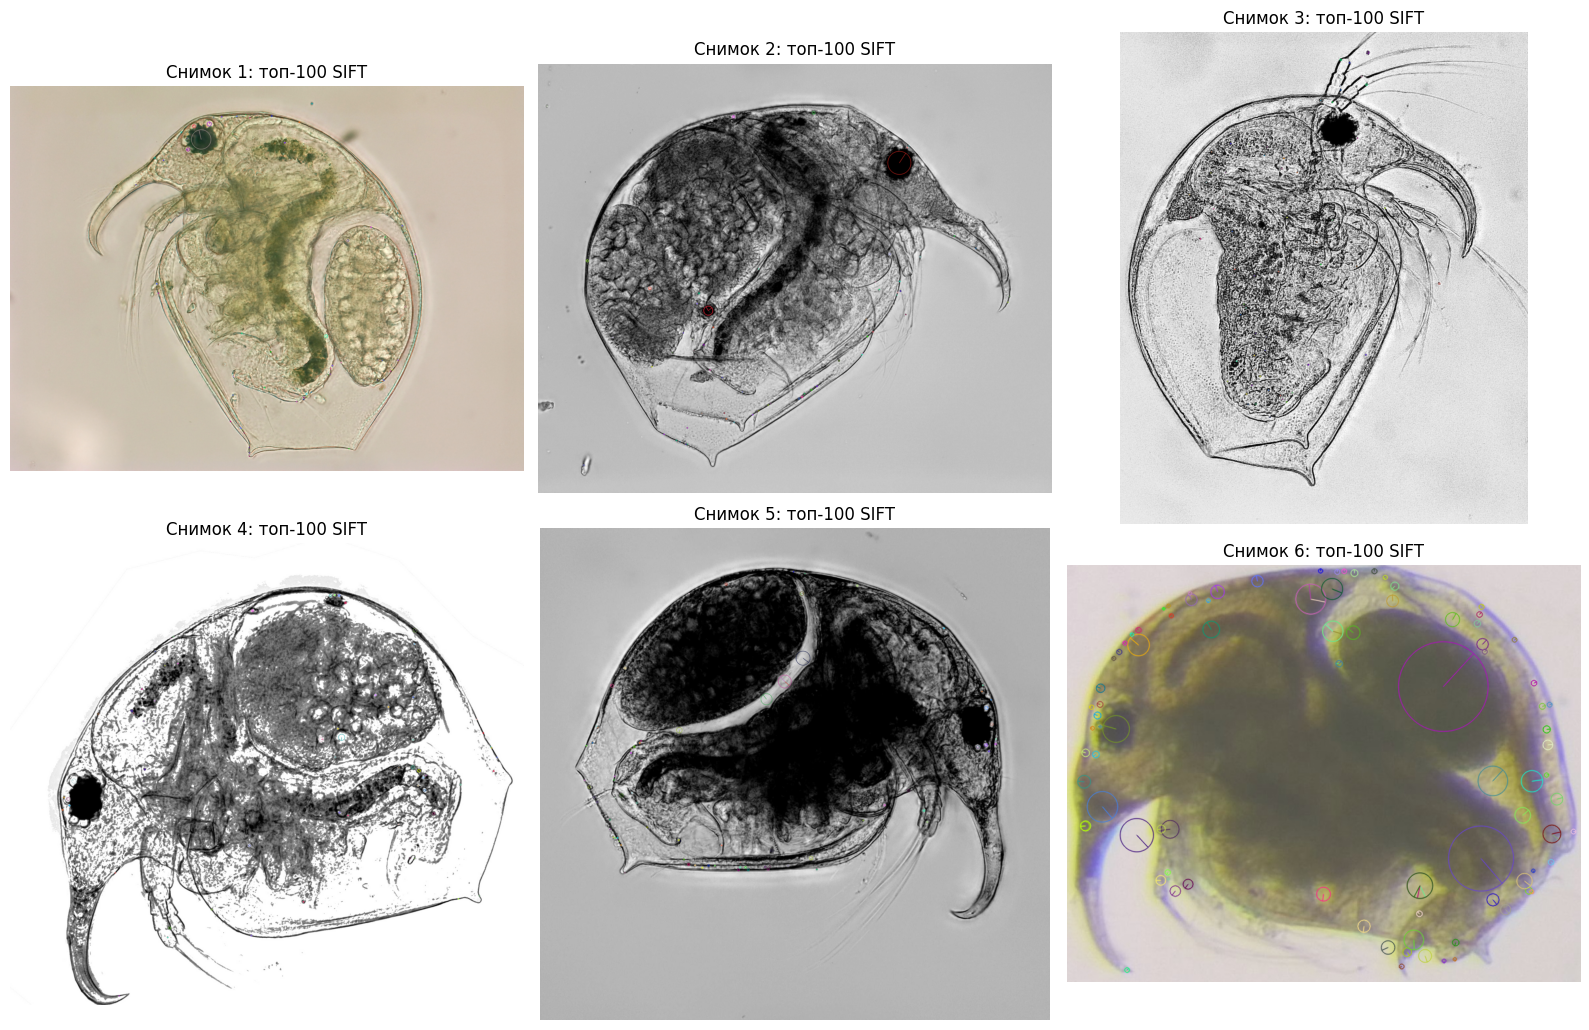

In [ ]:
keypoint_examples = []

for image, image_keypoints in zip(images_bgr, keypoints):
    strongest = sorted(
        image_keypoints,
        key=lambda point: point.response,
        reverse=True,
    )[:100]
    visualized = cv2.drawKeypoints(
        image,
        strongest,
        None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
    )
    keypoint_examples.append(visualized)

show_image_grid(
    keypoint_examples,
    [f"Снимок {number}: топ-100 SIFT" for number in range(1, len(image_paths) + 1)],
    RESULTS_DIR / "sift_keypoints.jpg",
)

## 4. Попарное сопоставление дескрипторов

Для всех 15 пар изображений делаем три последовательных проверки:

1. **Lowe ratio test:** ближайший дескриптор должен быть заметно ближе второго: \(d_1 < 0.75\,d_2\).
2. **Взаимность:** совпадение A→B должно быть подтверждено в обратном направлении B→A.
3. **RANSAC:** точки должны согласовываться с одним частичным аффинным преобразованием (сдвиг, вращение, масштаб), с порогом ошибки 5 px. Для подтверждения требуем не менее 4 инлайеров.

Используем `BFMatcher(NORM_L2)`: SIFT возвращает вещественные дескрипторы, для которых подходит евклидово расстояние.

In [6]:
matcher = cv2.BFMatcher(cv2.NORM_L2)


def filter_lowe_ratio(knn_matches, threshold=LOWE_RATIO):
    """Возвращает словарь {индекс исходной точки: лучший match}."""
    accepted = {}

    for neighbors in knn_matches:
        if len(neighbors) < 2:
            continue

        nearest, second_nearest = neighbors
        if nearest.distance < threshold * second_nearest.distance:
            accepted[nearest.queryIdx] = nearest

    return accepted


def geometric_inliers(matches, points_a, points_b):
    """Оставляет RANSAC-инлайеры при наличии >= 4 согласованных точек."""
    if len(matches) < 4:
        return []

    coordinates_a = np.float32([points_a[m.queryIdx].pt for m in matches])
    coordinates_b = np.float32([points_b[m.trainIdx].pt for m in matches])

    transform, inlier_mask = cv2.estimateAffinePartial2D(
        coordinates_a,
        coordinates_b,
        method=cv2.RANSAC,
        ransacReprojThreshold=RANSAC_THRESHOLD_PX,
        maxIters=3000,
        confidence=0.995,
    )

    if transform is None or inlier_mask is None:
        return []

    inliers = [
        match for match, accepted in zip(matches, inlier_mask.ravel())
        if accepted
    ]
    return inliers if len(inliers) >= 4 else []

In [7]:
pairwise_results = {}
summary_rows = []

for index_a, index_b in combinations(range(len(image_paths)), 2):
    forward_neighbors = matcher.knnMatch(
        descriptors[index_a], descriptors[index_b], k=2
    )
    backward_neighbors = matcher.knnMatch(
        descriptors[index_b], descriptors[index_a], k=2
    )

    forward = filter_lowe_ratio(forward_neighbors)
    backward = filter_lowe_ratio(backward_neighbors)

    mutual_matches = [
        match
        for match in forward.values()
        if match.trainIdx in backward
        and backward[match.trainIdx].trainIdx == match.queryIdx
    ]

    inlier_matches = geometric_inliers(
        mutual_matches,
        keypoints[index_a],
        keypoints[index_b],
    )

    pairwise_results[(index_a, index_b)] = {
        "mutual": mutual_matches,
        "inliers": inlier_matches,
    }
    summary_rows.append(
        {
            "Снимок A": index_a + 1,
            "Снимок B": index_b + 1,
            "После ratio test": len(forward),
            "Взаимные": len(mutual_matches),
            "После RANSAC": len(inlier_matches),
        }
    )

pair_table = pd.DataFrame(summary_rows)
display(pair_table)

,Снимок A,Снимок B,После ratio test,Взаимные,После RANSAC
0,1,2,15,1,0
1,1,3,5,1,0
2,1,4,13,3,0
3,1,5,24,0,0
4,1,6,20,1,0
5,2,3,14,5,0
6,2,4,20,7,0
7,2,5,20,3,0
8,2,6,31,1,0
9,3,4,8,5,0


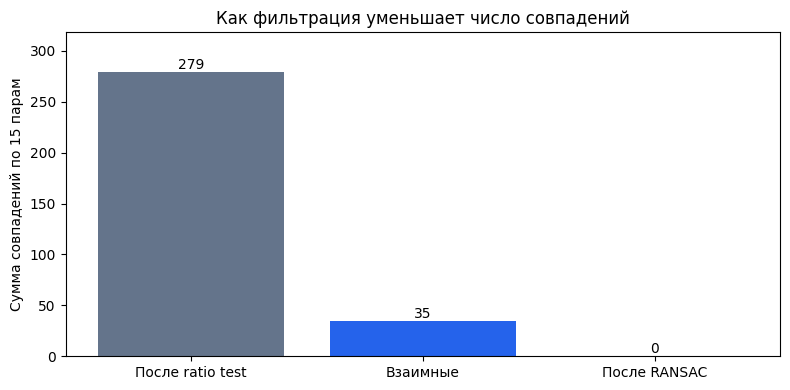

In [8]:
steps = ["После ratio test", "Взаимные", "После RANSAC"]
counts = pair_table[steps].sum()

fig, axis = plt.subplots(figsize=(8, 4))
bars = axis.bar(steps, counts.to_numpy(), color=["#64748b", "#2563eb", "#ea580c"])
axis.bar_label(bars)
axis.set_ylabel("Сумма совпадений по 15 парам")
axis.set_title("Как фильтрация уменьшает число совпадений")
axis.set_ylim(0, max(1, counts.max()) * 1.14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "filtering_stages.png", dpi=150)
plt.show()

## 5. Посмотрим на реальные совпадения

Берём пару с наибольшим числом **взаимных кандидатов**. Слева — линии, оставшиеся после ratio test и проверки взаимности; справа — только геометрически подтверждённые линии. Если во втором случае линий нет, это отражает результат RANSAC, а не ошибку отображения.

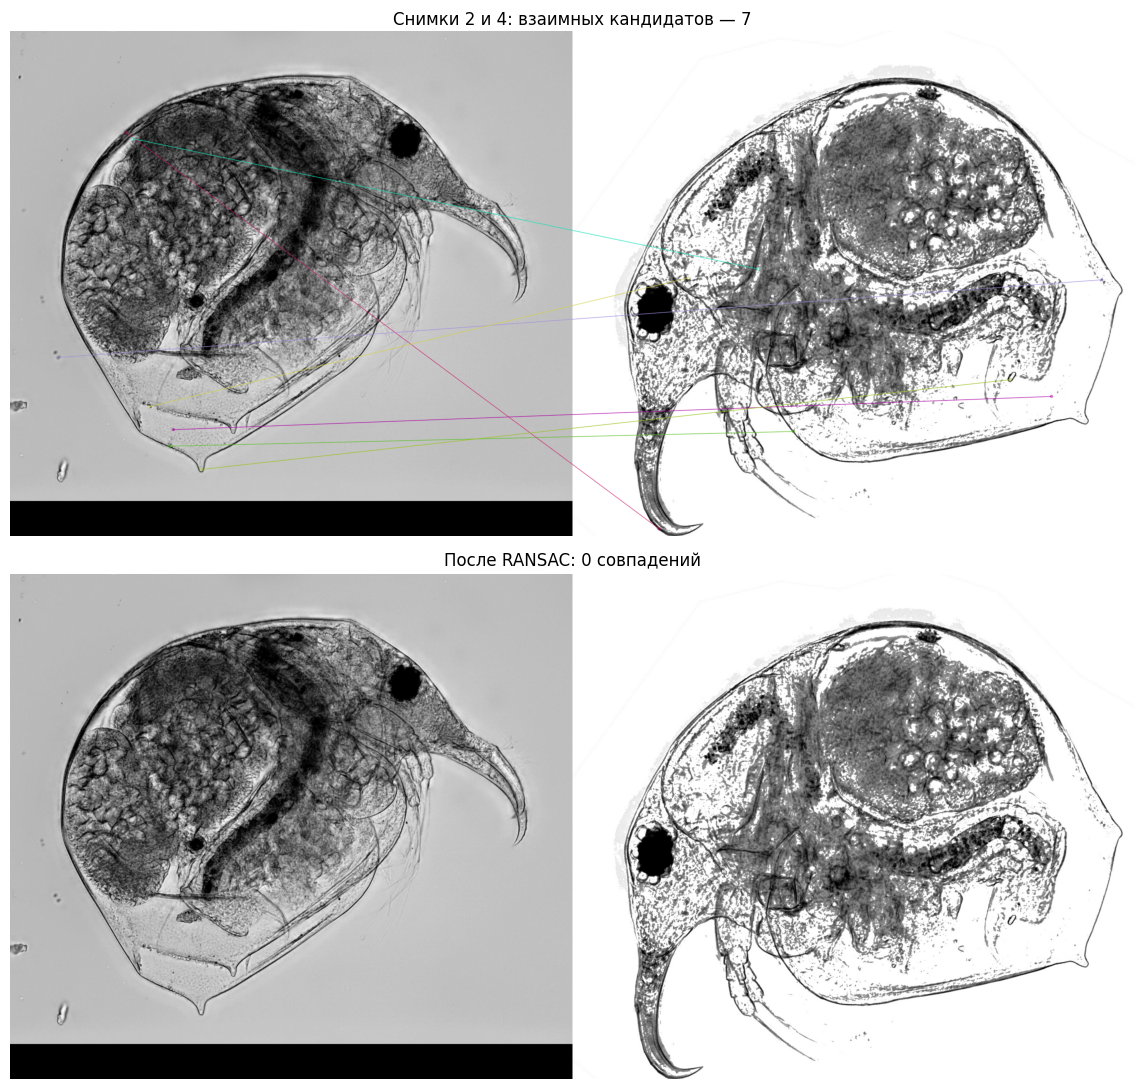

In [9]:
example_pair = max(
    pairwise_results,
    key=lambda pair: len(pairwise_results[pair]["mutual"]),
)
image_a, image_b = example_pair
candidates = pairwise_results[example_pair]["mutual"]
inliers = pairwise_results[example_pair]["inliers"]


def draw_match_preview(matches):
    preview = cv2.drawMatches(
        images_bgr[image_a], keypoints[image_a],
        images_bgr[image_b], keypoints[image_b],
        sorted(matches, key=lambda match: match.distance)[:30],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    return cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(2, 1, figsize=(15, 11))
axes[0].imshow(draw_match_preview(candidates))
axes[0].set_title(
    f"Снимки {image_a + 1} и {image_b + 1}: "
    f"взаимных кандидатов — {len(candidates)}"
)
axes[1].imshow(draw_match_preview(inliers))
axes[1].set_title(f"После RANSAC: {len(inliers)} совпадений")

for axis in axes:
    axis.axis("off")

fig.tight_layout()
fig.savefig(RESULTS_DIR / "pair_example.jpg", dpi=140, bbox_inches="tight")
plt.show()

## 6. Поиск точек, общих для **всех** изображений

Попарные совпадения ещё **не** означают общие точки для всех снимков. Для каждого SIFT-индекса на первом изображении пытаемся найти соответствующий индекс на каждом из остальных. Затем проверяем, что все выбранные точки согласованы **для каждой пары снимков**, а не только с первым изображением.

Получается строгий критерий: одна последовательность из N точек считается общей только тогда, когда подтверждены все N(N−1)/2 парных связей. Для шести фотографий это 15 проверок.

In [ ]:
def find_common_tracks(pair_results, number_of_images):
    """Ищет согласованные глобальные треки в геометрических инлайерах."""
    if number_of_images < 2:
        return []

    pair_maps = {
        pair: {m.queryIdx: m.trainIdx for m in data["inliers"]}
        for pair, data in pair_results.items()
    }

    reference_candidates = set(pair_maps[(0, 1)])
    for other_image in range(2, number_of_images):
        reference_candidates &= set(pair_maps[(0, other_image)])

    common_tracks = []
    for reference_index in sorted(reference_candidates):
        track = {0: reference_index}
        for other_image in range(1, number_of_images):
            track[other_image] = pair_maps[(0, other_image)][reference_index]

        all_pairs_agree = all(
            pair_maps[(index_a, index_b)].get(track[index_a]) == track[index_b]
            for index_a, index_b in combinations(range(number_of_images), 2)
        )
        if all_pairs_agree:
            common_tracks.append(track)

    return common_tracks


common_tracks = find_common_tracks(pairwise_results, len(image_paths))
common_tracks.sort(
    key=lambda track: -sum(
        keypoints[index][track[index]].response for index in range(len(image_paths))
    )
)
print(f"Общих точек на всех {len(image_paths)} снимках: {len(common_tracks)}")

Общих точек на всех 6 снимках: 0


## 7. Визуализация общих точек

Если общие точки найдены, их номера (1, 2, 3, …) **совпадают на всех фотографиях**. Максимум показываем 30 точек. При нулевом результате не подменяем их случайными похожими деталями.

Нет общих подтверждённых точек — изображения показаны без номеров.


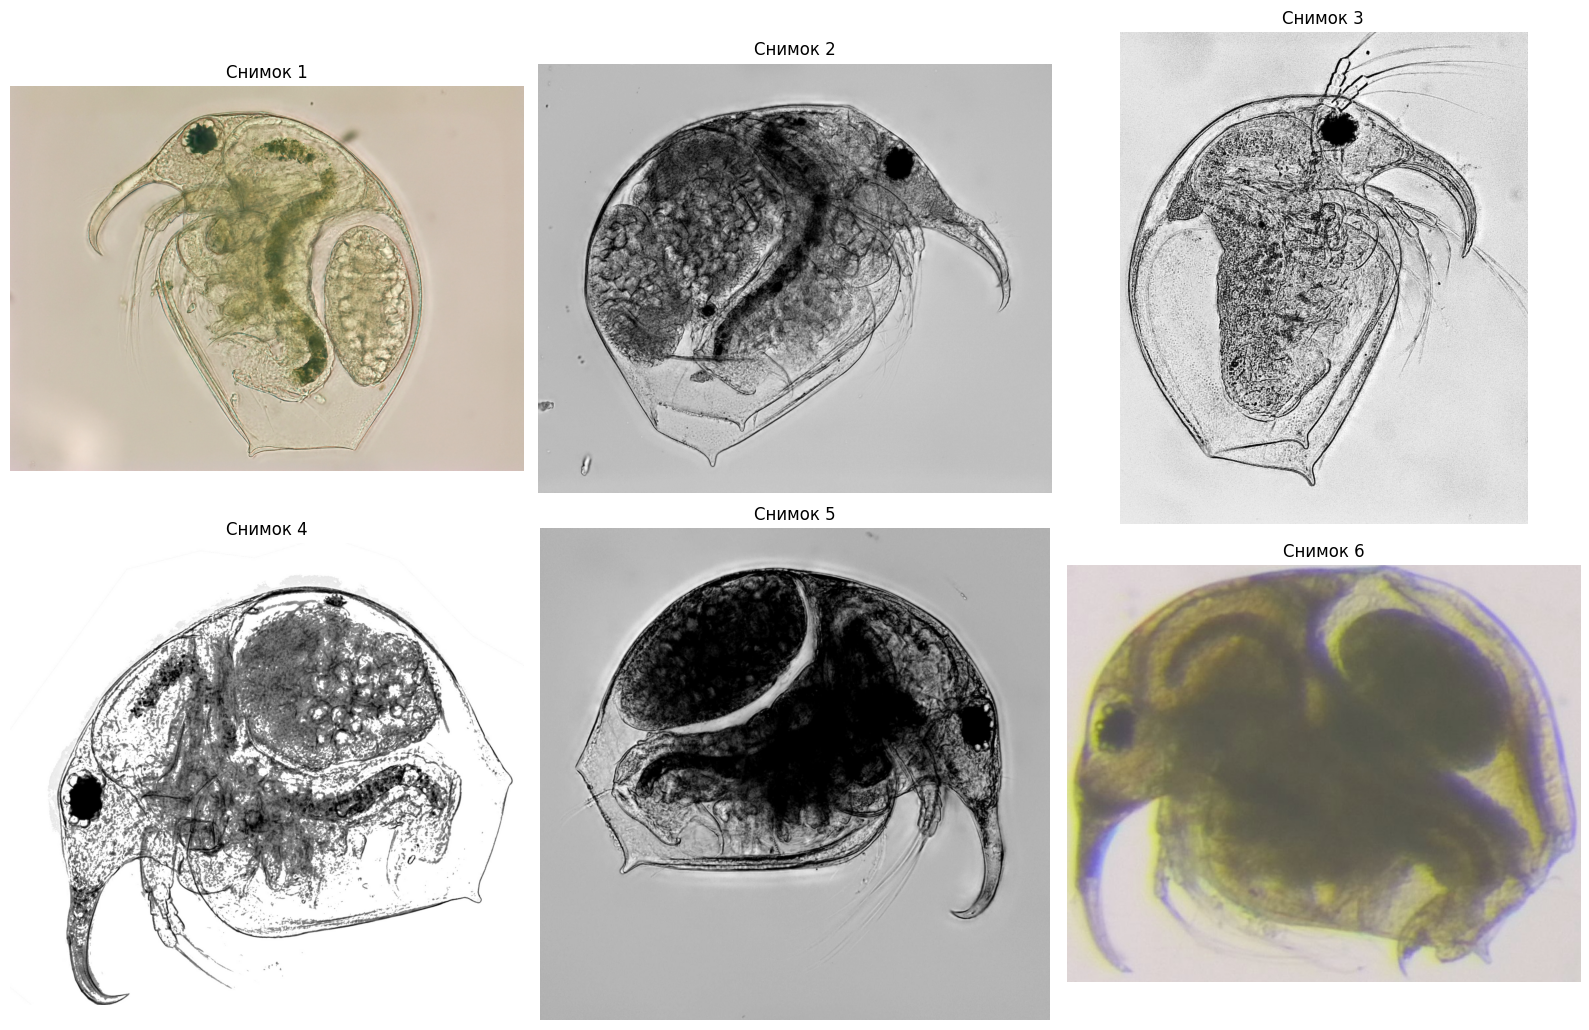

In [11]:
selected_tracks = common_tracks[:MAX_DISPLAY_POINTS]
numbered_points = []

for image_index in range(len(image_paths)):
    image_points = []
    for number, track in enumerate(selected_tracks, start=1):
        x, y = keypoints[image_index][track[image_index]].pt
        image_points.append((number, x, y))
    numbered_points.append(image_points)

if not selected_tracks:
    print("Нет общих подтверждённых точек — изображения показаны без номеров.")

show_image_grid(
    images_bgr,
    [f"Снимок {number}" for number in range(1, len(image_paths) + 1)],
    RESULTS_DIR / "common_points.jpg",
    points=numbered_points,
)

## 8. Сохранение метрик для PDF-отчёта

JSON удобен для проверки результата и повторной генерации отчёта. Все значения вычисляются из тех же переменных, что показаны в ноутбуке.

In [12]:
statistics = {
    "organism": "Bosmina longirostris",
    "images": [path.name for path in image_paths],
    "image_shapes": [list(image.shape[:2]) for image in images_bgr],
    "original_shapes": [[height, width] for width, height in original_sizes],
    "sift_points": [len(points) for points in keypoints],
    "params": {
        "max_side": MAX_IMAGE_SIDE,
        "ratio": LOWE_RATIO,
        "ransac_px": RANSAC_THRESHOLD_PX,
        "nfeatures": SIFT_FEATURE_LIMIT,
        "contrastThreshold": CONTRAST_THRESHOLD,
        "edgeThreshold": EDGE_THRESHOLD,
        "sigma": SIFT_SIGMA,
    },
    "pairs": [
        {
            "image_a": int(row["Снимок A"]),
            "image_b": int(row["Снимок B"]),
            "ratio_forward": int(row["После ratio test"]),
            "mutual": int(row["Взаимные"]),
            "geometry_inliers": int(row["После RANSAC"]),
        }
        for row in summary_rows
    ],
    "total_mutual": int(pair_table["Взаимные"].sum()),
    "total_geometry": int(pair_table["После RANSAC"].sum()),
    "global_tracks": len(common_tracks),
    "visualized": len(selected_tracks),
    "pair_example": [image_a + 1, image_b + 1],
}

output_path = RESULTS_DIR / "stats.json"
output_path.write_text(
    json.dumps(statistics, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print(f"Статистика сохранена: {output_path}")

Статистика сохранена: /mnt/data/plankton_clean/results/stats.json


## 9. Выводы

- SIFT обнаруживает многочисленные локальные особенности, однако на этих фотографиях большинство из них **не воспроизводится** при смене особи и ракурса.
- Устойчивые к масштабу и повороту дескрипторы не обеспечивают устойчивость к **изменению морфологии**, частичным перекрытиям и различиям качества снимков.
- Можно предположить, что узнаваемые анатомические ориентиры располагаются на **контуре панциря и в области придатков**. Но автоматический эксперимент **не подтвердил** надёжные точки этих областей на всех шести изображениях — это не следует выдавать за доказанный результат.
- Для настоящего поиска анатомических соответствий на *разных особях* уместнее разметка ориентиров (landmarks), регистрация формы или специальная обученная модель.

**Почему число общих точек равно нулю:** это корректный результат строгой последовательности проверок. Ослаблять пороги только для получения красивых чисел нельзя без независимой оценки ложных совпадений.

**Исходный код и PDF-отчёт:** [GitHub](https://github.com/igoryas27/plankton-keypoint-matching).